# 01. Does the projection budget behave the way the equations say?

**Question.** The OSP paper reserves an orthogonal subspace of size `r` for every unlearning
task, inside a layer whose input width is `d_in`. Three things follow from Eqs. 1 to 3 that the
paper never states. This notebook checks all three, with no training.

**What we measure.**

1. **T4, the budget.** Run more tasks than `floor(d_in / r)` and record the free dimensions
   and the size of each update. The equations say capacity runs out at `d_in / r`, and that
   every task after that produces an update of exactly zero.
2. **T7, lambda independence.** The paper labels its saturation figure `lambda = 2.0`, but
   lambda appears only in the fusion step (Eq. 1), never in training or the SVD. We scale the
   updates and check whether the free-rank curve moves. Scaling a matrix cannot change its
   column space, so it must not.
3. **T5, interference.** Build two updates whose input directions are orthogonal by
   construction, then check whether adding the second one changes behaviour the first one
   produced. The paper claims "zero interference with historical tasks".

**Decision rule, fixed before running.**

| Test | Supports the paper | Contradicts the paper |
|---|---|---|
| T4 | updates stay nonzero past `d_in / r` | `reserved == r` up to the budget, then `update_norm < 1e-10` |
| T7 | free-rank curve moves with scale | all curves identical |
| T5 | predictions unchanged by the second update | overlap `< 1e-8` while `argmax_change_fraction > 0` |

**Limitations.** This tests the paper **as written**: Eqs. 1 to 3 and the Lemma 1 discussion.
It cannot show what the authors' own code did, because that code is not published. The updates
here are random rather than trained, so this says nothing yet about the effective rank of a
real trained update. That is test T1, which needs M2 and M3. Interference is measured on one
fused pair, not a full sequence.

**Hardware.** CPU only, a few seconds, well under 1 MB of output. No GPU is requested, so
none is released at the end.

**Spec references.** Tests T4, T5, T7 and discrepancies D3, D4, D5 in `day-zero/paper_spec.md`.

## 1. Load code

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch

import src.common as common
from src.common import load_config, provenance, save_json
from src.diagnostics import budget_trace, interference

REPO = Path(common.__file__).resolve().parents[1]
PROV = provenance()

print("repo          :", REPO)
print("commit        :", PROV["commit"])
print("local changes :", PROV["git_status"] or "none")
print("python        :", PROV["python"].split()[0])
print("torch         :", PROV["torch"])

repo          : C:\LangChain\Algoverse\cl-ul-adapters
commit        : cf631fe080322ff6edabaf12be6c1c526996399b
local changes : ?? notebooks/
?? references-papers/
?? src/diagnostics.py
?? tests/test_diagnostics.py
python        : 3.14.6
torch         : 2.12.0+cpu


## 2. Settings

One configuration source. Everything below comes from `config.yaml`.

In [2]:
CFG = load_config(REPO / "config.yaml")
PROJ = CFG["projection"]
D_IN = CFG["model"]["feature_dim"]
D_OUT = CFG["model"]["classes"]
RANK = PROJ["rank"]
RANKS = [2, 4, 8]
SCALES = [0.5, 1.0, 2.0]
SEEDS = CFG["seeds"]
RUN = "nb01-projection-budget-checks"

print("resolved projection config:")
print(json.dumps(PROJ, indent=2))
print()
print(f"layer         : {D_IN} x {D_OUT}")
print(f"ranks swept   : {RANKS} -> predicted budgets {[D_IN // r for r in RANKS]} tasks")
print(f"scales swept  : {SCALES}")
print(f"seeds         : {SEEDS}")
print(f"planned work  : {len(RANKS)} budget traces, {len(SCALES)} scale traces, {len(SEEDS)} interference trials")
print("hardware      : CPU only")
print("runtime       : a few seconds (estimate, not measured)")
print("storage       : under 1 MB")

resolved projection config:
{
  "rank": 4,
  "rank_atol": 1e-12,
  "rank_rtol": 1e-08,
  "feasibility_atol": 1e-08,
  "feasibility_rtol": 1e-06,
  "dtype": "float64"
}

layer         : 64 x 100
ranks swept   : [2, 4, 8] -> predicted budgets [32, 16, 8] tasks
scales swept  : [0.5, 1.0, 2.0]
seeds         : [0, 1, 2]
planned work  : 3 budget traces, 3 scale traces, 3 interference trials
hardware      : CPU only
runtime       : a few seconds (estimate, not measured)
storage       : under 1 MB


## 3. Connect to storage

In [3]:
OUT = REPO / "outputs" / RUN
OUT.mkdir(parents=True, exist_ok=True)
print("writing results to", OUT)

writing results to C:\LangChain\Algoverse\cl-ul-adapters\outputs\nb01-projection-budget-checks


## 4. Prepare inputs

T5 needs a weight matrix and some input features. We prefer the real M0 cache, which holds the
public checkpoint's 64 by 100 head and the 10,000 CIFAR-100 test features. If that cache is
missing, we fall back to random Gaussian stand-ins and say so, because the conclusion should
not depend on which one we used.

In [4]:
caches = sorted((REPO / "outputs" / "m0").glob("*/test.pt"))
if caches:
    blob = torch.load(caches[0], map_location="cpu", weights_only=True)
    head = torch.load(caches[0].with_name("head.pt"), map_location="cpu", weights_only=True)
    FEATURES = blob["features"].double()
    WEIGHT = head["weight"].double()
    SOURCE = f"M0 cache {caches[0].parent.name[:12]} (real CIFAR-100 test features and head)"
else:
    generator = torch.Generator().manual_seed(0)
    FEATURES = torch.randn(10000, D_IN, generator=generator, dtype=torch.float64)
    WEIGHT = 0.1 * torch.randn(D_IN, D_OUT, generator=generator, dtype=torch.float64)
    SOURCE = "random Gaussian stand-in (M0 cache not found)"

print("input source :", SOURCE)
print("features     :", tuple(FEATURES.shape))
print("head weight  :", tuple(WEIGHT.shape))

input source : M0 cache 3383bea0e35b (real CIFAR-100 test features and head)
features     : (10000, 64)
head weight  : (64, 100)


### Resume

Not implemented, and not needed. Every measurement here runs in seconds and writes once at the
end. Claiming a resume boundary we do not have would be worse than having none.

## 5. Run the measurements

### T4: the capacity budget

In [5]:
traces = {r: budget_trace(D_IN, D_OUT, r, D_IN // r + 4, PROJ, seed=SEEDS[0]) for r in RANKS}
t4 = pd.concat([pd.DataFrame(rows).assign(rank=r) for r, rows in traces.items()], ignore_index=True)

print(f"rank {RANK}, the paper's setting. Budget is {D_IN} / {RANK} = {D_IN // RANK} tasks.")
display(t4[t4["rank"] == RANK].drop(columns="rank").to_string(index=False))

rank 4, the paper's setting. Budget is 64 / 4 = 16 tasks.


' task  free_rank_before  reserved  free_rank_after  update_norm\n    1                64         4               60 1.616135e+02\n    2                60         4               56 1.460273e+02\n    3                56         4               52 1.491170e+02\n    4                52         4               48 1.491550e+02\n    5                48         4               44 1.319209e+02\n    6                44         4               40 1.337361e+02\n    7                40         4               36 1.495672e+02\n    8                36         4               32 1.082507e+02\n    9                32         4               28 9.376629e+01\n   10                28         4               24 1.093263e+02\n   11                24         4               20 1.032286e+02\n   12                20         4               16 8.750071e+01\n   13                16         4               12 7.607980e+01\n   14                12         4                8 5.698750e+01\n   15                 8 

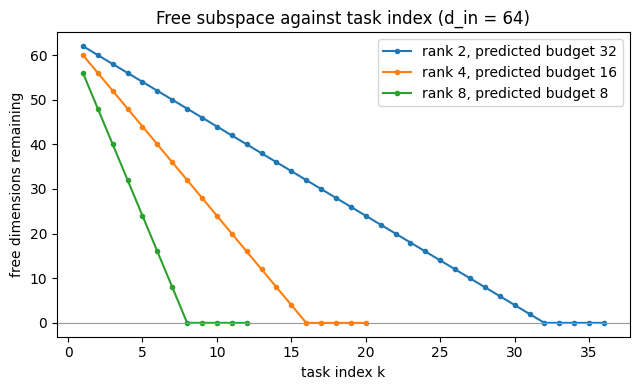

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for r, rows in traces.items():
    frame = pd.DataFrame(rows)
    ax.plot(frame["task"], frame["free_rank_after"], marker="o", ms=3,
            label=f"rank {r}, predicted budget {D_IN // r}")
ax.axhline(0, lw=0.8, color="0.6")
ax.set_xlabel("task index k")
ax.set_ylabel("free dimensions remaining")
ax.set_title(f"Free subspace against task index (d_in = {D_IN})")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "free_rank.png", dpi=150)
plt.show()

### T7: does the fusion strength lambda move the curve?

In [7]:
scale_curves = {
    s: [row["free_rank_after"]
        for row in budget_trace(D_IN, D_OUT, RANK, 20, PROJ, seed=SEEDS[0], scale=s)]
    for s in SCALES
}
T7_IDENTICAL = len({tuple(curve) for curve in scale_curves.values()}) == 1

for s, curve in scale_curves.items():
    print(f"scale {s:>4}: {curve[:18]}")
print("\nall curves identical:", T7_IDENTICAL)

scale  0.5: [60, 56, 52, 48, 44, 40, 36, 32, 28, 24, 20, 16, 12, 8, 4, 0, 0, 0]
scale  1.0: [60, 56, 52, 48, 44, 40, 36, 32, 28, 24, 20, 16, 12, 8, 4, 0, 0, 0]
scale  2.0: [60, 56, 52, 48, 44, 40, 36, 32, 28, 24, 20, 16, 12, 8, 4, 0, 0, 0]

all curves identical: True


### T5: do orthogonal input subspaces act independently?

In [8]:
t5 = pd.DataFrame([
    {"seed": s, **interference(WEIGHT, FEATURES, RANK, PROJ, seed=s, strength=1.0)}
    for s in SEEDS
])
display(t5.to_string(index=False))
print()
print(t5.drop(columns="seed").agg(["mean", "std"]).to_string())

' seed  input_subspace_overlap  frobenius_inner_product  argmax_change_fraction  mean_logit_shift  mean_logit_norm_after_first\n    0            1.795784e-16             2.664535e-14                  0.9166        349.752342                   260.944628\n    1            1.161350e-16            -7.815970e-14                  0.7344        232.542276                   347.046336\n    2            2.047205e-16            -7.815970e-14                  0.4375        230.993024                   432.465272'


      input_subspace_overlap  frobenius_inner_product  argmax_change_fraction  mean_logit_shift  mean_logit_norm_after_first
mean            1.668113e-16            -4.322468e-14                0.696167        271.095881                   346.818745
std             4.565190e-17             6.050923e-14                0.241828         68.122898                    85.760548


## 6. Interpret

Method checks first, then the comparison. Each line is scored against the decision rule
written at the top, before any result was seen.

In [9]:
BUDGET_OK = all(
    all(row["reserved"] == r for row in rows[: D_IN // r])
    and all(row["update_norm"] < 1e-10 for row in rows[D_IN // r:])
    for r, rows in traces.items()
)
GEOMETRY_OK = bool((t5["input_subspace_overlap"].abs() < 1e-8).all())
BEHAVIOUR_CHANGES = bool((t5["argmax_change_fraction"] > 0).all())

print(f"T4  budget is d_in / r, updates past it are zero  : {BUDGET_OK}")
print(f"T7  free-rank curve does not depend on scale      : {T7_IDENTICAL}")
print(f"T5  input subspaces are orthogonal                : {GEOMETRY_OK}   (paper's geometric claim)")
print(f"T5  predictions still change after the 2nd update : {BEHAVIOUR_CHANGES}   (paper's behavioural claim fails)")
print()
print("Consequences for the spec:")
print(f"  D3 (N=20 and N=30 sit past the budget)      : supported by T4  = {BUDGET_OK}")
print(f"  D4 (Fig. 3's lambda label cannot matter)    : supported by T7  = {T7_IDENTICAL}")
print(f"  D5 ('zero interference' is false as stated) : supported by T5  = {GEOMETRY_OK and BEHAVIOUR_CHANGES}")
print()
print("Still open: D2, the 23-versus-0 conflict. It needs T1, the effective rank of a")
print("real trained update, which arrives with M2 and M3. Nothing here settles it.")

T4  budget is d_in / r, updates past it are zero  : True
T7  free-rank curve does not depend on scale      : True
T5  input subspaces are orthogonal                : True   (paper's geometric claim)
T5  predictions still change after the 2nd update : True   (paper's behavioural claim fails)

Consequences for the spec:
  D3 (N=20 and N=30 sit past the budget)      : supported by T4  = True
  D4 (Fig. 3's lambda label cannot matter)    : supported by T7  = True
  D5 ('zero interference' is false as stated) : supported by T5  = True

Still open: D2, the 23-versus-0 conflict. It needs T1, the effective rank of a
real trained update, which arrives with M2 and M3. Nothing here settles it.


### Plain-language summary

House rule: every notebook ends with its result written in simple English, short sentences, no
jargon that was not defined. This cell prints that summary from the numbers above, so it cannot
drift away from what was actually measured.

In [10]:
budget = D_IN // RANK
overlap = t5["input_subspace_overlap"].mean()
flipped = 100 * t5["argmax_change_fraction"].mean()

print(f'''
The layer reads {D_IN} numbers. Each unlearning task uses {RANK} directions of those {D_IN}.
{D_IN} divided by {RANK} is {budget}. So after {budget} tasks, no direction is free.

We ran {budget + 4} tasks. Every task after number {budget} produced an update of size zero.
Those tasks changed nothing at all. This is what the paper's own equations predict.

We then changed the adapter size to {RANKS}. The limit moved to {[D_IN // r for r in RANKS]} tasks.
That is exactly what the division predicts. The rule holds, it is not a one-off.

Lambda is the strength number in the paper's fusion step. We multiplied the updates by
{SCALES}. The curve of free directions did not move at all. So the paper's Figure 3,
which is labelled "lambda = 2.0", shows a quantity that cannot depend on lambda.

Last test. We built two updates that use completely separate input directions. Their
overlap was {overlap:.1e}, which is zero in practice. The paper's geometry is correct.
But adding the second update still changed the predicted class for {flipped:.1f}% of inputs.
So separate directions do not mean the two tasks leave each other alone.

What this does not show: what the authors' real code did. We only tested the method as the
paper describes it. We also used random updates, not trained ones.
''')


The layer reads 64 numbers. Each unlearning task uses 4 directions of those 64.
64 divided by 4 is 16. So after 16 tasks, no direction is free.

We ran 20 tasks. Every task after number 16 produced an update of size zero.
Those tasks changed nothing at all. This is what the paper's own equations predict.

We then changed the adapter size to [2, 4, 8]. The limit moved to [32, 16, 8] tasks.
That is exactly what the division predicts. The rule holds, it is not a one-off.

Lambda is the strength number in the paper's fusion step. We multiplied the updates by
[0.5, 1.0, 2.0]. The curve of free directions did not move at all. So the paper's Figure 3,
which is labelled "lambda = 2.0", shows a quantity that cannot depend on lambda.

Last test. We built two updates that use completely separate input directions. Their
overlap was 1.7e-16, which is zero in practice. The paper's geometry is correct.
But adding the second update still changed the predicted class for 69.6% of inputs.
So separate di

## 7. Save and verify

Write the artifacts, then reopen and parse every one of them.

In [11]:
t4.to_csv(OUT / "budget_trace.csv", index=False)
t5.to_csv(OUT / "interference.csv", index=False)

save_json(OUT / "metadata.json", {
    "notebook": "notebooks/01_projection_budget_checks.ipynb",
    "run_label": RUN,
    "spec_tests": ["T4", "T5", "T7"],
    "spec_discrepancies": ["D3", "D4", "D5"],
    "protocol": "Synthetic checks of Eqs. 1-3 as written. No training and no reproduction of the paper's experiments.",
    "interpretation_rule": (
        "T4 passes if reserved == rank for every task up to floor(d_in/rank) and update norm < 1e-10 after that. "
        "T7 passes if the free-rank curves are identical across scales. "
        "T5 contradicts the paper if subspace overlap < 1e-8 while argmax_change_fraction > 0."
    ),
    "limitations": [
        "Tests the paper as specified, not the authors' unpublished implementation.",
        "Updates are random, not trained. Effective rank of a trained update is test T1.",
        "Interference is measured on one fused pair, not across a full task sequence.",
    ],
    "results": {
        "T4_budget_ok": BUDGET_OK,
        "T7_scale_invariant": T7_IDENTICAL,
        "T5_geometry_ok": GEOMETRY_OK,
        "T5_behaviour_changes": BEHAVIOUR_CHANGES,
        "interference_mean": {k: float(v) for k, v in t5.drop(columns="seed").mean().items()},
    },
    "input_source": SOURCE,
    "config_projection": PROJ,
    "seeds": SEEDS, "ranks": RANKS, "scales": SCALES,
    "provenance": PROV,
})

for path in sorted(OUT.iterdir()):
    print(f"{path.name:22s} {path.stat().st_size:>9,d} bytes")

assert len(pd.read_csv(OUT / "budget_trace.csv")) == len(t4)
assert len(pd.read_csv(OUT / "interference.csv")) == len(t5)
assert json.loads((OUT / "metadata.json").read_text(encoding="utf-8"))["run_label"] == RUN
print("\nreopened and verified")

budget_trace.csv           2,249 bytes
free_rank.png             67,471 bytes
interference.csv             401 bytes
metadata.json              3,216 bytes

reopened and verified


## 8. Release the GPU

Not applicable. This notebook never requested a GPU, so there is nothing to release.